# 10 - Đánh giá Tập Test Duy nhất (S5-04, S5-05)

**Bài tập lớn môn Học máy:** Phân loại 4 nhóm ảnh X-quang ngực (`COVID`, `Lung_Opacity`, `Normal`, `Viral Pneumonia`).  
**Mô hình và đặc trưng đã đóng băng:** `orig_to_orig` = `StandardScaler` (chỉ fit trên train) + `SVC(kernel='rbf', C=10.0, gamma='scale', class_weight='balanced', probability=True, random_state=42)` trên 152 chiều đặc trưng ghép `ghep` (Histogram 64 + GLCM 60 + LBP 28), ảnh gốc xám 299×299 (`results/rq3_shortcut_learning_conclusion.md`).  
**Biên bản quy trình:** `results/final_test_protocol_record.md` (D1–D4, G1–G6, chốt chặn hạ tầng và kiểm toán phiên bản).  
**Người phụ trách (Code Owner):** Nguyễn Hải Lý (duyệt Cả nhóm).

## Mục tiêu thực hiện:
1. **Kiểm toán vết mở khóa G6 (`UNLOCK_RECORD.json`):** Xác minh tính toàn vẹn của thời điểm UTC, commit hash, SHA256 split và tái lập val G5.
2. **Báo cáo hiệu năng tổng thể trên tập test (S5-04):** Điểm ước lượng Macro-F1 kèm khoảng tin cậy 95% bootstrap 2.000 lần theo ảnh, Accuracy, Balanced Accuracy và chênh lệch so với validation (Test − Val).
3. **Chỉ số chi tiết từng lớp và Ma trận nhầm lẫn 4×4 (S5-05):** Precision, Recall, F1 từng lớp và ma trận con nhầm lẫn 2×2 giữa `Normal` và `Lung_Opacity` (R2).
4. **Phân tích sai số lấy mẫu (R4) và Giới hạn mô hình (R5):** Tuân thủ tuyệt đối quy tắc **D4**: báo cáo đúng số đo được, mọi lời giải thích chỉ là giả thuyết chưa kiểm chứng, không suy diễn nguyên nhân.


In [1]:
from __future__ import annotations

import json
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Định vị thư mục gốc của repository
REPO_ROOT = Path.cwd()
if not (REPO_ROOT / 'results' / 'threshold_v3.md').exists() and (REPO_ROOT.parent / 'results' / 'threshold_v3.md').exists():
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.metrics import DEFAULT_CLASS_NAMES

RESULTS_DIR = REPO_ROOT / 'results'
FINAL_DIR = RESULTS_DIR / 'final_test'

print(f'Thư mục gốc dự án: {REPO_ROOT}')
print(f'Thư mục kết quả final test: {FINAL_DIR}')
assert FINAL_DIR.is_dir(), f'Chưa tìm thấy thư mục {FINAL_DIR}'


Thư mục gốc dự án: D:\Use Antigravity\Medical Vision
Thư mục kết quả final test: D:\Use Antigravity\Medical Vision\results\final_test


## 1. Kiểm toán Bản ghi Mở khóa Test (Gate G6 & UNLOCK_RECORD.json)


In [2]:
unlock_path = FINAL_DIR / 'UNLOCK_RECORD.json'
assert unlock_path.is_file(), f'Thiếu tệp {unlock_path}'

unlock_rec = json.loads(unlock_path.read_text(encoding='utf-8'))
print('=== THÔNG TIN BẢN GHI MỞ KHÓA (G6) ===')
print(f"- Thời điểm mở khóa (UTC): {unlock_rec['utc_time']}")
print(f"- Commit SHA             : {unlock_rec['commit']}")
print(f"- Split SHA-256          : {unlock_rec['split_sha256']}")
print(f"- Val Macro-F1 tái lập  : {unlock_rec['val_macro_f1']:.4f}")
print(f"- Hash xác nhận G4       : {unlock_rec['confirm_sha256']}")

REFERENCE_VAL_F1 = 0.9024
diff_g5 = abs(unlock_rec['val_macro_f1'] - REFERENCE_VAL_F1)
assert diff_g5 <= 0.002, f'G5 thất bại: sai lệch {diff_g5:.6f} > 0.002'
print(f'\n=> CỔNG G5: ĐẠT (sai lệch |Δ| = {diff_g5:.6f} <= 0.002 so với mốc 0.9024)')


=== THÔNG TIN BẢN GHI MỞ KHÓA (G6) ===
- Thời điểm mở khóa (UTC): 2026-11-09T07:43:34Z
- Commit SHA             : 5720e4fdb6c1d827b800e51ef8be5559fe191dd6
- Split SHA-256          : f99e03d3d5cfc32f2bbc9befbdef45a07a256458a837a6d420a6658ed7583d98
- Val Macro-F1 tái lập  : 0.9024
- Hash xác nhận G4       : 9e935a10a3593fe72a6901ae2edbe232fc7a35f002af13bc9cb33cad02a689a2

=> CỔNG G5: ĐẠT (sai lệch |Δ| = 0.000045 <= 0.002 so với mốc 0.9024)


## 2. Báo cáo Hiệu năng Tổng thể trên Tập Test (S5-04)


In [3]:
report_path = FINAL_DIR / 'final_test_report.json'
metrics_path = FINAL_DIR / 'metrics.json'
assert report_path.is_file() and metrics_path.is_file()

report = json.loads(report_path.read_text(encoding='utf-8'))
metrics = json.loads(metrics_path.read_text(encoding='utf-8'))

overall_df = pd.DataFrame([
    {
        'Tập dữ liệu': 'Validation (Tham chiếu)',
        'Số mẫu (N)': 3174,
        'Macro-F1': f"{report['val_macro_f1']:.4f}",
        '95% CI Bootstrap': '-',
        'Accuracy': '0.8986',
    },
    {
        'Tập dữ liệu': 'Test (Đánh giá 1 lần)',
        'Số mẫu (N)': 3176,
        'Macro-F1': f"{report['macro_f1']:.4f}",
        '95% CI Bootstrap': f"[{report['ci95_low']:.4f}, {report['ci95_high']:.4f}]",
        'Accuracy': f"{report['accuracy']:.4f}",
    },
])

print('=== SO SÁNH HIỆU NĂNG VALIDATION VÀ TEST (S5-04) ===')
display(overall_df)

test_minus_val = report['test_minus_val']
print(f'\n- Hiệu số học (Test − Val): {test_minus_val:+.4f} (Macro-F1 sụt giảm {abs(test_minus_val)*100:.2f}%)')
print(f"- Độ rộng khoảng tin cậy 95% (R4): {report['r4_sampling_error']['ci_width']:.4f} (với 2.000 lần lấy mẫu theo ảnh)")


=== SO SÁNH HIỆU NĂNG VALIDATION VÀ TEST (S5-04) ===


,Tập dữ liệu,Số mẫu (N),Macro-F1,95% CI Bootstrap,Accuracy
0,Validation (Tham chiếu),3174,0.9024,-,0.8986
1,Test (Đánh giá 1 lần),3176,0.8714,"[0.8579, 0.8840]",0.8656



- Hiệu số học (Test − Val): -0.0310 (Macro-F1 sụt giảm 3.10%)
- Độ rộng khoảng tin cậy 95% (R4): 0.0261 (với 2.000 lần lấy mẫu theo ảnh)


## 3. Chỉ số Hiệu năng Chi tiết từng Lớp Bệnh lý (S5-05)


In [4]:
per_class_data = []
for cls_name in DEFAULT_CLASS_NAMES:
    cls_stats = report['per_class'][cls_name]
    per_class_data.append({
        'Lớp bệnh lý': cls_name,
        'Số mẫu (Support)': cls_stats['support'],
        'Precision': f"{cls_stats['precision']:.4f}",
        'Recall': f"{cls_stats['recall']:.4f}",
        'F1-Score': f"{cls_stats['f1']:.4f}",
    })

per_class_df = pd.DataFrame(per_class_data)
print('=== HIỆU NĂNG PHÂN LOẠI TỪNG LỚP TRÊN TẬP TEST ===')
display(per_class_df)


=== HIỆU NĂNG PHÂN LOẠI TỪNG LỚP TRÊN TẬP TEST ===


,Lớp bệnh lý,Số mẫu (Support),Precision,Recall,F1-Score
0,COVID,543,0.9257,0.9171,0.9214
1,Lung_Opacity,904,0.8013,0.8296,0.8152
2,Normal,1529,0.8844,0.8659,0.8751
3,Viral Pneumonia,200,0.8634,0.8850,0.8741


## 4. Ma trận Nhầm lẫn 4×4 và Ma trận Con Normal – Lung_Opacity (R2)


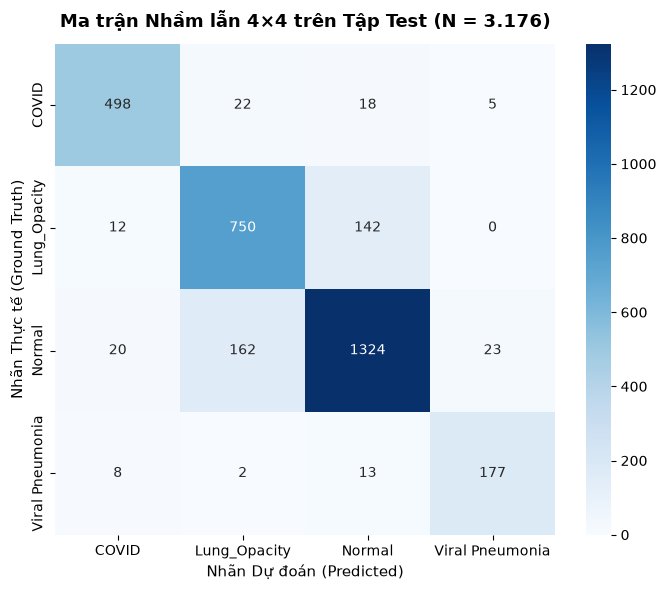

=== MA TRẬN CON NORMAL vs LUNG_OPACITY (Báo cáo bắt buộc R2) ===


,Dự đoán: Lung_Opacity,Dự đoán: Normal
Thực tế: Lung_Opacity,750,142
Thực tế: Normal,162,1324


- Tổng số mẫu nhầm lẫn giữa Normal và Lung_Opacity: 304 mẫu
- Tỷ lệ chiếm trong tổng số mẫu nhầm lẫn toàn tập test: 304/427 (71.19%)


In [5]:
cm = np.array(report['confusion_matrix'])

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=DEFAULT_CLASS_NAMES,
    yticklabels=DEFAULT_CLASS_NAMES,
)
plt.title('Ma trận Nhầm lẫn 4×4 trên Tập Test (N = 3.176)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Nhãn Dự đoán (Predicted)', fontsize=11)
plt.ylabel('Nhãn Thực tế (Ground Truth)', fontsize=11)
plt.tight_layout()
plt.savefig(FINAL_DIR / 'confusion_matrix_test.png', dpi=300)
plt.show()

r2 = report['r2_normal_lung_opacity']
r2_df = pd.DataFrame(
    [
        [r2['LO_to_LO'], r2['LO_to_Normal']],
        [r2['Normal_to_LO'], r2['Normal_to_Normal']],
    ],
    index=['Thực tế: Lung_Opacity', 'Thực tế: Normal'],
    columns=['Dự đoán: Lung_Opacity', 'Dự đoán: Normal'],
)

print('=== MA TRẬN CON NORMAL vs LUNG_OPACITY (Báo cáo bắt buộc R2) ===')
display(r2_df)

total_r2_errors = r2['LO_to_Normal'] + r2['Normal_to_LO']
total_errors = int(np.sum(cm) - np.trace(cm))
print(f'- Tổng số mẫu nhầm lẫn giữa Normal và Lung_Opacity: {total_r2_errors} mẫu')
print(f'- Tỷ lệ chiếm trong tổng số mẫu nhầm lẫn toàn tập test: {total_r2_errors}/{total_errors} ({total_r2_errors / total_errors * 100:.2f}%)')


## 5. Báo cáo Giới hạn và Lưu ý Diễn giải Khoa học (D4 & R5)


In [6]:
r5_path = FINAL_DIR / 'r5_gioi_han.md'
assert r5_path.is_file()

print('=== NỘI DUNG BÁO CÁO GIỚI HẠN R5 & LƯU Ý D4 ===')
print(r5_path.read_text(encoding='utf-8'))

print('\n=== LƯU Ý BẮT BUỘC THEO QUY ĐỊNH D4 ===')
print(f"\"{report['interpretation_note']}\"")


=== NỘI DUNG BÁO CÁO GIỚI HẠN R5 & LƯU Ý D4 ===
# Báo cáo giới hạn (R5) - Đánh giá tập test duy nhất (S5-04, S5-05)

- **Val Macro-F1**: 0.9024
- **Test Macro-F1**: 0.8714 (95% CI: [0.8579, 0.8840])
- **Hiệu số (Test - Val)**: -0.0310

## Lưu ý giải thích kết quả (D4):
Moi loi giai thich ve su khac biet giua val va test deu la gia thuyet chua kiem chung; khong suy dien nguyen nhan.


=== LƯU Ý BẮT BUỘC THEO QUY ĐỊNH D4 ===
"Moi loi giai thich ve su khac biet giua val va test deu la gia thuyet chua kiem chung; khong suy dien nguyen nhan."
